# GPU acceleration

Five estimators run part of their work on the GPU: `UMAPGpu`, `DensMAPGpu`,
`TSNEGpu`, `DREAMSGpu` and `PHATEGpu`. The backend is wgpu, so there is no
CUDA runtime to install, and the same wheel runs on Metal, Vulkan and DX12.
This vignette covers what actually moves to the device, what it buys you, and
the sharp edges.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import manifolds_rs as mf

pl.Config.set_fmt_str_lengths(60)


def scatter(
    ax: plt.Axes, emb: np.ndarray, c: np.ndarray, title: str, cmap: str = "tab10"
) -> None:
    """One embedding, coloured by `c`, without axis ticks."""
    ax.scatter(emb[:, 0], emb[:, 1], c=c, s=1, cmap=cmap, alpha=0.6)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def panels(
    embeddings: dict[str, np.ndarray], c: np.ndarray, cmap: str = "tab10"
) -> None:
    """A row of embeddings sharing one colouring."""
    fig, axes = plt.subplots(
        1, len(embeddings), figsize=(4.3 * len(embeddings), 4.3), squeeze=False
    )
    for ax, (name, emb) in zip(axes[0], embeddings.items(), strict=True):
        scatter(ax, emb, c, name, cmap)
    fig.tight_layout()


def timed(fn) -> float:
    """Wall time of one call, in seconds."""
    start = time.perf_counter()
    fn()
    return time.perf_counter() - start

One call answers both questions you have: was this build compiled with GPU
support, and is there an adapter?

In [2]:
mf.gpu_available()

True

## What moves to the device

Not everything.

- `UMAPGpu` and `DensMAPGpu`: the neighbour search and the optimiser.
  `"adam_gpu"` (default) is the parallel Adam on the device, `"adam_v06_gpu"`
  the umap-learn 0.6 Adam. The CPU names still work and run the optimiser on
  the CPU after a GPU search. Graph construction and initialisation stay on
  the CPU. densMAP's density term runs on the device with `"adam_gpu"`; the
  radii come back to the host in between so the correlation statistics can
  accumulate in float64. The 0.6 Adam has no density term, so `DensMAPGpu`
  refuses every `"adam_v06"` name.
- `TSNEGpu` and `DREAMSGpu`: the neighbour search always. With
  `approx="fft_3k_gpu"` the whole optimisation stays on the device too: the
  three-kernel FFT repulsion, with the embedding resident between epochs. The
  other `approx` values run on the CPU after the GPU search.
- `PHATEGpu`: the neighbour search and, with spectral landmarks, the
  randomised SVD and k-means of the landmark selection. Diffusion time,
  powering, MDS and interpolation stay on the CPU.

Same data on both sides first, to see the pictures agree.

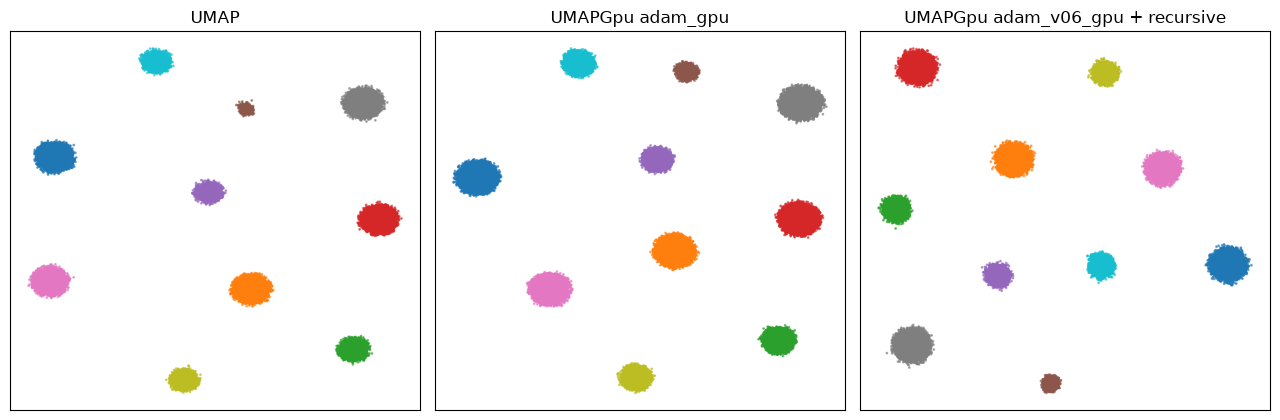

In [3]:
X, y = mf.datasets.clustered(25_000)
X_traj, y_traj = mf.datasets.trajectory(25_000)
order = np.random.default_rng(42).permutation(len(y_traj))

panels(
    {
        "UMAP": mf.UMAP().fit_transform(X),
        "UMAPGpu adam_gpu": mf.UMAPGpu().fit_transform(X),
        "UMAPGpu adam_v06_gpu + recursive": mf.UMAPGpu(
            optimiser="adam_v06_gpu", init="recursive"
        ).fit_transform(X),
    },
    y,
)

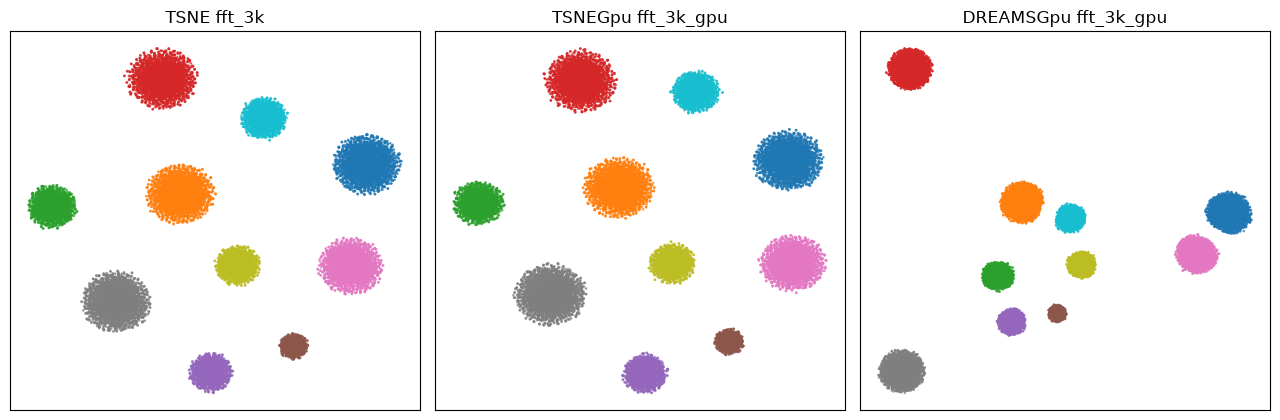

In [4]:
panels(
    {
        "TSNE fft_3k": mf.TSNE(approx="fft_3k").fit_transform(X),
        "TSNEGpu fft_3k_gpu": mf.TSNEGpu(approx="fft_3k_gpu").fit_transform(X),
        "DREAMSGpu fft_3k_gpu": mf.DREAMSGpu(approx="fft_3k_gpu").fit_transform(X),
    },
    y,
)

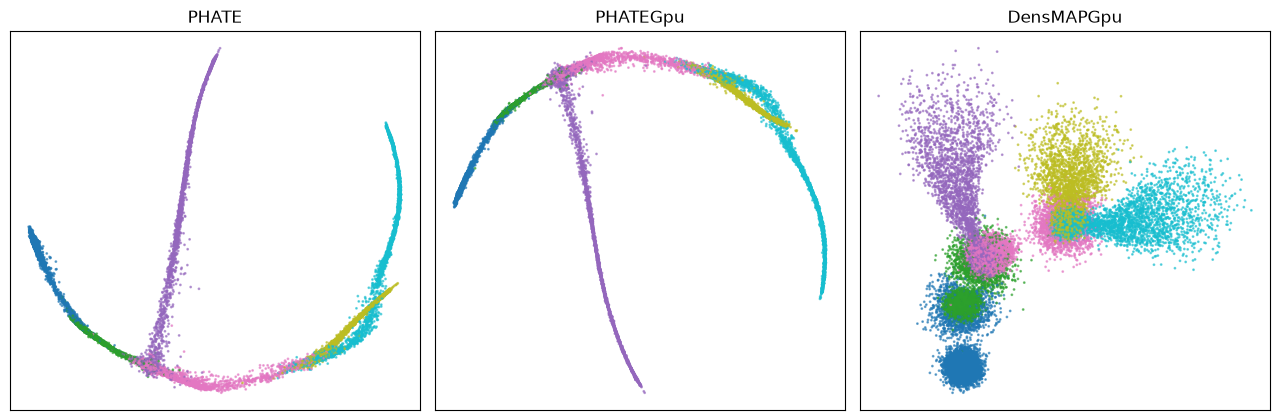

In [5]:
panels(
    {
        "PHATE": mf.PHATE().fit_transform(X_traj)[order],
        "PHATEGpu": mf.PHATEGpu().fit_transform(X_traj)[order],
        "DensMAPGpu": mf.DensMAPGpu().fit_transform(X_traj)[order],
    },
    y_traj[order],
)

Same pictures on both sides. DREAMS sits apart because it is pulled towards
its PCA reference, which is the point of it.

## Is it faster?

That depends on whether the neighbour search and the optimiser were your
bottleneck. On a few thousand points they won't be, and the transfers make
the GPU slower than the CPU. Here are 200k points in 50 dimensions, one run
each, wall time in seconds, neighbour search included.

In [6]:
X_big, _ = mf.datasets.clustered(200_000)
X_big32 = X_big.astype(np.float32)

runs = {
    "UMAP": lambda: mf.UMAP().fit_transform(X_big32),
    "UMAPGpu": lambda: mf.UMAPGpu().fit_transform(X_big32),
    "TSNE fft_3k": lambda: mf.TSNE(approx="fft_3k").fit_transform(X_big32),
    "TSNEGpu fft_3k_gpu": lambda: mf.TSNEGpu(approx="fft_3k_gpu").fit_transform(
        X_big32
    ),
    "PHATE": lambda: mf.PHATE().fit_transform(X_big32),
    "PHATEGpu": lambda: mf.PHATEGpu().fit_transform(X_big32),
}
pl.DataFrame(
    [{"method": k, "seconds": timed(fn)} for k, fn in runs.items()]
).with_columns(pl.col("seconds").round(2))

method,seconds
str,f64
"""UMAP""",8.16
"""UMAPGpu""",3.01
"""TSNE fft_3k""",14.88
"""TSNEGpu fft_3k_gpu""",5.04
"""PHATE""",8.31
"""PHATEGpu""",5.57


Both sides get float32 input, so the CPU side is not paying for float64. On
the M1 Max these notebooks were executed on, the GPU is two and a half to
three times faster for UMAP and t-SNE and about 1.5 times for PHATE, whose
diffusion and MDS stay on the CPU. Measure on your own data and hardware
before switching.

## Precision

WGSL has no float64, so the GPU estimators run in float32 at any size. `fit`
casts your input down, float64 included, and the embedding comes back as
float32. That is the only silent narrowing of your input in the package. If
it matters for your data, stay on the CPU estimators, which keep your dtype.
PCA initialisation still runs in float64 on the CPU and is cast back.

In [7]:
mf.UMAPGpu().fit_transform(X[:2_000]).dtype

dtype('float32')

## Reproducibility

GPU embeddings are reproducible in structure, not always in coordinates. The
device neighbour searches are not bit-stable at scale, and 500 epochs of Adam
turn a tiny difference in the graph into visibly different coordinates. The
clusters, branches and separations come back; the exact positions may not.
The Adam update itself is bit-stable given a fixed graph, so hand in a
pre-computed graph and a GPU run is reproducible too.

In [8]:
idx, dist = mf.knn_graph(X, k=15, ann="nndescent")
{
    "same graph, run twice": np.array_equal(
        mf.UMAPGpu().fit_transform(X, knn_indices=idx, knn_distances=dist),
        mf.UMAPGpu().fit_transform(X, knn_indices=idx, knn_distances=dist),
    )
}

{'same graph, run twice': True}

PHATE picks its diffusion time from the graph, so a different backend can pick
a different `t`. Pin `t` when you compare runs.

## Neighbour backends

The device backends are not the CPU ones with a suffix. `"nndescent_gpu"`
runs NN-Descent on the device and is the default for `UMAPGpu`, `DensMAPGpu`
and `PHATEGpu`. `TSNEGpu` and `DREAMSGpu` ask for `3 * perplexity`
neighbours and default to `"ivf_gpu"`, which holds up better at that `k`.
`"exhaustive_gpu"` is the third. A CPU-only name like `"hnsw"` is an error,
not a silent fallback. The knobs live in `NeighbourParamsGpu`, a different set
from the CPU `NeighbourParams`.

In [9]:
mf.NeighbourParamsGpu()

NeighbourParamsGpu(n_list=None, n_probes=None, k_means=None, k_build=None, n_tree=None, delta=None, rho=None)

## Mixing CPU and GPU

The neighbour graph is two arrays, so build it wherever it is cheapest and
hand it to whichever estimator you like. The graph above came from the CPU;
here it feeds the GPU optimiser, and the GPU search is skipped entirely.

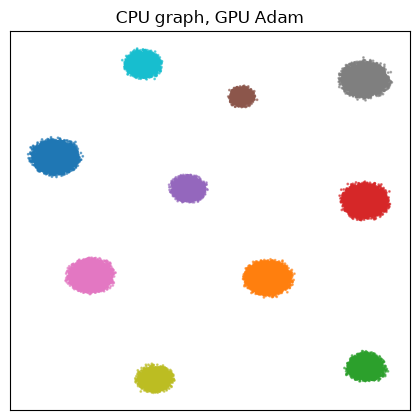

In [10]:
panels(
    {
        "CPU graph, GPU Adam": mf.UMAPGpu().fit_transform(
            X, knn_indices=idx, knn_distances=dist
        )
    },
    y,
)

## Headless machines and CI

`gpu_available()` returns `False` on a box with no adapter rather than
raising, and the GPU estimators still import. That is deliberate: a hosted CI
runner can prove the GPU wheel builds and degrades cleanly without a device.
It cannot prove the kernels are correct. That needs a runner with a GPU.

## MLX on Apple Silicon

There is a second Apple GPU path, through
[MLX](https://github.com/ml-explore/mlx) via mlx-c, and it is not in the
published wheel. It links mlx-c dynamically, so a wheel carrying it fails to
import on any Mac without the library. Build it yourself:

```sh
brew install mlx-c
maturin develop --release --features mlx
```

`mf.mlx_available()` is `True` only in an mlx build that found mlx-c. MLX is
not a separate set of estimators; the CPU estimators gain a few extra names:

```python
mf.UMAP(ann="nndescent_mlx", optimiser="adam_mlx").fit_transform(X)
mf.UMAP(optimiser="adam_v06_mlx", init="recursive").fit_transform(X)
mf.DensMAP(optimiser="adam_mlx").fit_transform(X)
mf.TSNE(ann="nndescent_mlx", approx="fft_3k_mlx").fit_transform(X)
mf.DREAMS(approx="fft_3k_mlx").fit_transform(X)
mf.PHATE(ann="nndescent_mlx", landmark_method="spectral_mlx").fit_transform(X)
mf.knn_graph(X, k=15, ann="ivf_mlx")
```

The neighbour backends are `"exhaustive_mlx"`, `"ivf_mlx"` and
`"nndescent_mlx"`. `TSNEGpu` and `DREAMSGpu` take `approx="fft_3k_mlx"` as
well, with the search on wgpu and the optimiser on MLX. `PHATEGpu` takes
`landmark_method="spectral_mlx"` the same way. den-SNE has no MLX path, and
`DiffusionMaps` keeps its landmark selection on the CPU. Everything MLX runs
in float32. In a build without MLX these names are refused with a pointer to
the build flag.

Is it worth the trouble? See the
[wgpu vs MLX benchmarks](https://github.com/GregorLueg/manifolds-rs/blob/main/docs/benchmarks_mlx.md).